# 2.31 · To smooth or not: smoothing, objectivity and model error

**Before this:** [2.09](2-09_regularisation_smoothing.ipynb) (smoothing priors), [2.13](2-13_model_errors_cd_cp.ipynb) (C_d and C_p), [2.18](2-18_gradients_hmc_nuts.ipynb) (NUTS), [2.29](2-29_hyperparameters_information_criteria.ipynb) (evidence and prior width),
2.30 (hierarchical Bayes)  
**You will be able to:** compare a regularised and an unregularised Bayesian slip inversion on the same data; tell a
profile from a marginal treatment of the smoothing weight; smooth a posterior after sampling; add a model-error
covariance C_p; say what "objective" does and does not mean  
**Optional sections:** 6 (evidence and prior width)

2.30 showed how hierarchical Bayes lets the data choose the smoothing weight. That answers *how much* to smooth. It
does not answer *whether* slip is smooth at all: the smoothing operator is still an assumption. Zhao & Jiang (2026)
press exactly this point against the Fukuda & Johnson approach, and Jiang & Simons (2016) show the alternative route:
a weak prior, an explicit model-error covariance $C_p$, and smoothing applied to the posterior afterwards. This
notebook rebuilds each argument on a toy that runs in a few minutes.

**The toy is a 1-D analogue, not a reproduction.** Zhao & Jiang invert 3-D strike-slip faults with dense InSAR and
GNSS; here slip varies only with depth on an antiplane fault seen by one line of stations. Absolute numbers will
differ from theirs. What we test are the mechanisms, and where a mechanism depends on an implementation detail that
their main text does not give, we say so.

**Words this notebook defines:** regularised (BR) vs unregularised (BUR) Bayesian inversion, smoothing form vs
smoothing weight, profile vs marginal treatment of a hyperparameter, renormalising a bounded prior, posterior
averaging, model prediction error $C_p$, misfit covariance $C_\chi$, prior-width dependence of the evidence, total
correlation, objectivity.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| depth-varying slip on a vertical strike-slip fault (sections 1-2, 4, 6) | 12 patches of 2 km (0-24 km), + α² for BR | 40 stations on one side, 0.5-60 km, σ_d = 0.5, 1, 2 or 5 cm | antiplane screw dislocation, $\mathbf d = \mathbf G\mathbf m$ | linear, bounded |
| coseismic slip and afterslip (section 3) | 12 + 12 patches | 40 + 40 stations | same | linear, bounded |
| slip with an imperfect forward model (section 5) | 12 patches | 40 stations, generated with all depths scaled by $1+\theta$ | same, with structural error | linear in slip |

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
from scipy.optimize import lsq_linear
from scipy.special import ndtr, ndtri
import jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

T0 = time.time()
BUR, EQ9, PROF, HIER, REN, RENLOG = ("BUR", "BR · eq. 9 as printed", "BR · profile", "BR · hierarchical",
                                     "BR · renormalised", "BR · renormalised, log α² prior")
MCOL = {BUR: S.ORANGE, EQ9: S.BLUE, PROF: S.VIOLET, HIER: S.AQUA, REN: S.MUTED, RENLOG: S.INK2}   # BUR orange, BR green as in Zhao & Jiang
C_TRUE = S.INK

# ---------------------------------------------------------------- the toy fault
M = 12
z_edges = np.linspace(0.0, 24.0, M + 1)              # 2-km patches down to 24 km
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
LF = z_edges[1] - z_edges[0]                          # patch size (km)
SHALLOW, DEEP = zc < 6, zc > 6                        # the well-resolved zone and the rest (resolution printout below)
xs = np.geomspace(0.5, 60.0, 40)                      # stations on one side (mirror stations add no new information)
Nd = xs.size


def greens(depth_scale=1.0):
    """Surface displacement (cm) per metre of slip on each patch; depth_scale stretches all depths (structural error)."""
    z = z_edges * depth_scale
    return 100.0 * np.array([[(np.arctan(z[j + 1] / x) - np.arctan(z[j] / x)) / np.pi for j in range(M)] for x in xs])


G = greens()
E_BND = 0.08


def bounds(s_m):
    """Zhao & Jiang's design: U(-e, 1+e) s_m above 12 km, zero-mean U(-0.2, 0.2) m below (their Ridgecrest values)."""
    return np.where(zc <= 12.0, -E_BND * s_m, -0.2), np.where(zc <= 12.0, (1 + E_BND) * s_m, 0.2)


lb, ub = bounds(2.0)                                  # s_m = 2 m, our choice for peaks of 1.4-1.6 m

# Laplacian as in Zhao & Jiang's eq. 7, sum over neighbours of (s_j - s_i) / L^2. Free surface at the top, a zero-slip
# ghost patch below 24 km, so D'D is full rank (Fukuda & Johnson 2008: "L^T L must be a full-rank matrix").
Dop = np.zeros((M, M))
for i in range(M):
    for j in (i - 1, i + 1):
        if 0 <= j < M:
            Dop[i, j] += 1.0
            Dop[i, i] -= 1.0
Dop[M - 1, M - 1] -= 1.0
Dop /= LF ** 2
DtD = Dop.T @ Dop
logdetDtD = np.linalg.slogdet(DtD)[1]
Sig_D = np.linalg.inv(DtD)                            # prior covariance per unit alpha^2
A2 = np.geomspace(1e-5, 1e5, 161)                     # Zhao & Jiang's range for alpha^2 (here in m^2 km^-4)
LA = np.log(A2)

TRUTHS = {
    "Gaussian patch (Test 1 analogue)": 1.59 * np.exp(-0.5 * ((zc - 3.0) / 1.58) ** 2),
    "sharp step at 4 km": np.where(zc < 4, 1.5, 0.0),
    "two shallow asperities": np.where(zc < 2, 1.4, 0.0) + np.where((zc > 4) & (zc < 6), 1.0, 0.0),
    "rough random (T3.1 analogue)": np.where(zc <= 12, np.random.default_rng(11).uniform(0, 1.6, M)
                                             * np.interp(zc, [0, 12], [1.0, 0.3]), 0.0),
}

# how well this geometry resolves each depth: resolution-matrix diagonal with a weak N(0, 1 m^2) prior
sv = np.linalg.svd(G, compute_uv=False)
for sig in [0.5, 1.0, 2.0, 5.0]:
    Rm = np.linalg.solve(G.T @ G / sig ** 2 + np.eye(M), G.T @ G / sig ** 2)
    print(f"sigma_d {sig:3.1f} cm: {np.sum(sv / sig > 1):d} slip combinations above the noise; resolution per patch "
          + " ".join(f"{r:.2f}" for r in np.diag(Rm)))

sigma_d 0.5 cm: 5 slip combinations above the noise; resolution per patch 1.00 0.98 0.69 0.35 0.29 0.24 0.19 0.16 0.16 0.19 0.24 0.30
sigma_d 1.0 cm: 4 slip combinations above the noise; resolution per patch 1.00 0.95 0.55 0.33 0.24 0.19 0.16 0.15 0.15 0.17 0.20 0.23
sigma_d 2.0 cm: 4 slip combinations above the noise; resolution per patch 1.00 0.90 0.43 0.29 0.20 0.16 0.14 0.14 0.14 0.15 0.16 0.17
sigma_d 5.0 cm: 3 slip combinations above the noise; resolution per patch 0.99 0.76 0.30 0.21 0.16 0.13 0.12 0.11 0.11 0.10 0.10 0.09


Read the resolution printout first (one number per patch, top to bottom; 1 = fully resolved). It is the diagonal
of the resolution matrix (reminder: 2.07), the share of each patch's true slip that reappears in its own estimate. In this 1-D geometry the
stations resolve the top two patches almost completely, the 4-6 km patch partly, and little below. Zhao & Jiang's
dense 3-D data resolve more; their Test 2 found that "the relative resolution ratio determines posterior model
resolutions" (p. 9). To compare like with like we put the features we want to recover in the top 6 km, and we report
errors separately for 0-6 km (resolved) and 6-24 km (poorly resolved).

## 1. The question: an objective weight on an assumed form

**In plain words.** A smoothing prior says two things: that neighbouring patches slip alike (the *form*), and how
strongly (the *weight*). ABIC and hierarchical Bayes estimate the weight from the data, which is why Fukuda & Johnson
call the result "objective smoothing". The form is still chosen by the analyst. If the real slip has sharp edges, no
weight makes a Laplacian prior right; the data can only pick the least wrong amount of smoothing.

**Precisely.** The regularised model (BR) is
$$p(\mathbf m\mid\alpha^2) \propto (2\pi\alpha^2)^{-N_m/2}\,|\mathbf D^\top\mathbf D|^{1/2}\exp\!\Big(-\frac{\lVert\mathbf D\mathbf m\rVert^2}{2\alpha^2}\Big)\ \text{inside the bounds } \mathbf m_{\min}\le\mathbf m\le\mathbf m_{\max},\qquad p(\alpha^2)\ \text{uniform on }[10^{-5},10^{5}],$$
with the Laplacian $\mathbf D$ (the papers write $\mathbf L$): for each patch, the sum of its differences from its
neighbours, a second-difference roughness operator (reminder: 2.09). The prefactor is the prior's normalising
constant (2.29) and $|\cdot|$ the determinant (2.06). The unregularised model (BUR) keeps only the bounds:
$p(\mathbf m) = \prod_j \mathcal U(m_{\min,j}, m_{\max,j})$, independent uniform distributions (2.03). Both use the same
likelihood $p(\mathbf d\mid\mathbf m)\propto\exp[-\tfrac12(\mathbf d-\mathbf G\mathbf m)^\top C_\chi^{-1}(\mathbf d-\mathbf G\mathbf m)]$, with
$C_\chi = C_d + C_p$ the misfit covariance (measurement plus prediction error; reminder: 2.13, and section 5 here). Zhao &
Jiang describe "a Bayesian unregularized (BUR) approach based solely on prior distributions of slip on a discretized
fault, and a Bayesian regularized (BR) approach incorporating explicit Laplacian‐based smoothing constraints (Section 2)
partly motivated by previous approaches (Fukuda & Johnson, 2008, 2010)" (p. 3). Our bounds follow their design:
$\mathcal U(-e, 1+e)\,s_m$ with $e = 0.08$ above 12 km and a zero-mean $\mathcal U(-0.2, 0.2)$ m below.

alpha^2 for the BR prior draws: 9.62e-05 m^2 km^-4 (largest prior sd 1 m)
saved figures/2-31_two_priors.png


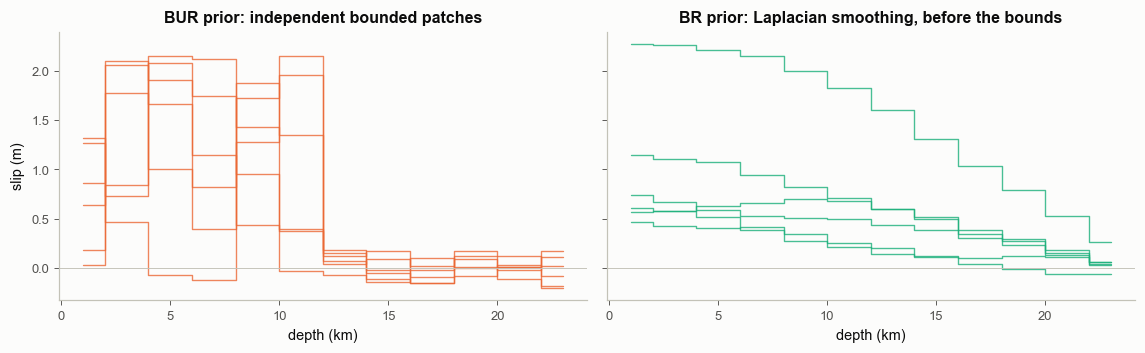

In [2]:
rng = np.random.default_rng(0)
a2_draw = 1.0 / Sig_D.diagonal().max()                # chosen so that the largest prior sd is 1 m
print(f"alpha^2 for the BR prior draws: {a2_draw:.2e} m^2 km^-4 (largest prior sd 1 m)")
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True)
for k in range(6):
    axs[0].step(zc, rng.uniform(lb, ub), where="mid", color=MCOL[BUR], lw=0.9, alpha=0.8)
    axs[1].step(zc, rng.multivariate_normal(np.zeros(M), a2_draw * Sig_D), where="mid", color=MCOL[HIER], lw=0.9, alpha=0.8)
axs[0].set_title("BUR prior: independent bounded patches")
axs[1].set_title("BR prior: Laplacian smoothing, before the bounds")
for ax in axs:
    ax.axhline(0, color=S.AXIS, lw=0.6)
    ax.set_xlabel("depth (km)")
axs[0].set_ylabel("slip (m)")
fig.tight_layout()
bk.savefig(fig, "2-31_two_priors")
plt.show()

**How to read it.** Each line is one draw from a prior. BUR draws jump independently from patch to patch inside their
bounds (positive above 12 km, near zero below). BR draws are smooth curves, free at the surface and tied to the
zero-slip patch below 24 km. Before any data arrive, BR already prefers smooth slip; BUR prefers nothing except the
bounds.

**Common misreadings.**
* "Hierarchical smoothing is assumption-free because the weight is estimated." The weight is estimated; the operator
  $\mathbf D$, its boundary rows and the hyperprior are not.
* "BUR has no prior." It has bounds and a depth design, and its posterior mean is pulled toward the middle of the
  bounds wherever the data are weak (section 2 shows this).

## 2. BUR vs BR, and which BR

Zhao & Jiang's BR is a hybrid: "For each sampled α², ms is estimated via bound‐constrained least‐squares inversions
with Laplacian smoothing" (p. 5), the posterior is evaluated with their eq. 9, and "The resultant ensemble of optimal
slip models, marginalized over α², defines the posterior slip distributions. The key difference between BUR and BR
lies in the first step: BUR directly samples ms, whereas BR only samples α² and then solves slip through
optimization" (p. 6). Between that scheme and a fully hierarchical model lie three separate choices. We change them
one at a time and keep BUR as the reference:

| step | what changes | label |
|---|---|---|
| 0 | eq. 9 as printed: for each α², the optimal slip; score = misfit + roughness/α² | BR · eq. 9 as printed |
| 1 | add the smoothing prior's normalising factor $(\alpha^2)^{-N_m/2}\lvert\mathbf D^\top\mathbf D\rvert^{1/2}$ (Fukuda & Johnson 2008, eq. 9) | BR · profile |
| 2 | integrate over slip instead of taking the optimum: sample slip and α² jointly; the bounds truncate the joint density | BR · hierarchical |
| 3 | renormalise the smoothing prior inside the bounds for every α² | BR · renormalised |
| 4 | as 3, with a uniform prior on ln α² instead of on α² | BR · renormalised, log α² prior |

**Precisely.** Steps 0-1 evaluate the joint density at its maximum over slip for each α², which is a *profile*: the
slip is replaced by its single best value instead of being averaged over, like judging a mountain range by its highest
peak rather than by its whole volume. Step 2 integrates slip out (the marginal likelihood of 2.29 and 2.30). In the
formula below, $\ln|\cdot|$ is a log-determinant (2.06): the last term measures how much the data plus prior narrow
the slip, and it is the term a profile drops. For the Gaussian part (bounds aside) the result has the structure of Fukuda & Johnson's eq. A7
(2008, p. 1145):
$$\ln p(\mathbf d\mid\alpha^2) = -\tfrac12\chi^2(\bar{\mathbf m}) - \frac{\lVert\mathbf D\bar{\mathbf m}\rVert^2}{2\alpha^2} - \frac{N_m}{2}\ln\alpha^2 + \tfrac12\ln|\mathbf D^\top\mathbf D| - \tfrac12\ln\big|\mathbf G^\top C_d^{-1}\mathbf G + \mathbf D^\top\mathbf D/\alpha^2\big| + \text{const}.$$
Step 1 keeps the first four terms, step 0 the first two. Step 3 concerns the bounds: inside them the smoothing prior
integrates to $P(\text{bounds}\mid\alpha^2) = \int_{\text{bounds}} \mathcal N(\mathbf m;\mathbf 0,\alpha^2(\mathbf D^\top\mathbf D)^{-1})\,d\mathbf m$,
not to 1. Fukuda & Johnson divide by this constant for their positivity bound ("Zprior is a constant that is
introduced to normalize p(s|α²)", 2008, p. 1131). For the positive orthant alone it does not depend on α² (2.30, section
3); for a box with upper bounds it does. We compute $\ln P(\text{bounds}\mid\alpha^2)$ with the GHK simulator
(Geweke-Hajivassiliou-Keane). Plain Monte Carlo would draw slip vectors from the prior and count the share inside the
box, which fails when that share is tiny. GHK writes the Gaussian with its Cholesky factor (2.06), so that patch $j$
depends only on the patches before it; it then draws patch 1 inside its bounds, patch 2 inside its bounds given
patch 1, and so on, multiplying the probabilities that each step could land inside. The average of that product over
many such sequential draws estimates the box probability, and no draw is wasted outside the box.

Slip and α² are sampled with NumPyro NUTS (2.18; dense mass matrix, one chain of 1500 draws after 600 warm-up steps,
2.19); the profile steps use bounded least squares (least squares with every slip kept inside its bounds) on the α²
grid, which is exact for one hyperparameter.

In [3]:
Gj, Dj, LAj = jnp.asarray(G), jnp.asarray(Dop), jnp.asarray(LA)


def model_bur(d, sig, lo, hi):
    m = numpyro.sample("m", dist.Uniform(lo, hi))
    numpyro.sample("d", dist.Normal(Gj @ m, sig), obs=d)


def model_br(d, sig, lo, hi, log_pb, linear):
    """Hierarchical BR. log_pb = ln P(bounds | alpha^2) on the grid (zeros: no renormalisation);
    linear = 1: uniform prior on alpha^2 (both papers), 0: uniform prior on ln alpha^2."""
    la2 = numpyro.sample("log_a2", dist.Uniform(LA[0], LA[-1]))
    numpyro.factor("hyperprior", linear * la2)
    m = numpyro.sample("m", dist.Uniform(lo, hi))
    numpyro.factor("smoothing_prior", -0.5 * jnp.sum((Dj @ m) ** 2) * jnp.exp(-la2) - 0.5 * M * la2
                   - jnp.interp(la2, LAj, log_pb))
    numpyro.sample("d", dist.Normal(Gj @ m, sig), obs=d)


def model_bur_cov(d, chol_chi, lo, hi):
    m = numpyro.sample("m", dist.Uniform(lo, hi))
    numpyro.sample("d", dist.MultivariateNormal(Gj @ m, scale_tril=chol_chi), obs=d)


_MC = {}


def sample(model, *args, seed=0):
    """NumPyro NUTS, compiled once per model and reused for new data (jit_model_args)."""
    if model.__name__ not in _MC:
        _MC[model.__name__] = MCMC(NUTS(model, dense_mass=True, target_accept_prob=0.9), num_warmup=600,
                                   num_samples=1500, num_chains=1, progress_bar=False, jit_model_args=True)
    mc = _MC[model.__name__]
    mc.run(jax.random.PRNGKey(seed), *[jnp.asarray(a) for a in args], extra_fields=("diverging",))
    out = {k: np.asarray(v) for k, v in mc.get_samples().items()}
    out["div"] = int(np.asarray(mc.get_extra_fields()["diverging"]).sum())
    return out


def log_pbounds(lo, hi, n=20000, seed=0):
    """GHK estimate of ln P(lo <= m <= hi | alpha^2), m ~ N(0, alpha^2 (D'D)^-1), on the alpha^2 grid."""
    C = np.linalg.cholesky(Sig_D)
    rng = np.random.default_rng(seed)
    out = []
    for a2 in A2:
        al = np.sqrt(a2)
        u, lw = np.zeros((n, M)), np.zeros(n)
        for j in range(M):
            shift = u[:, :j] @ C[j, :j]
            a, b = (lo[j] / al - shift) / C[j, j], (hi[j] / al - shift) / C[j, j]
            flip = a > 0                                      # work in the thinner tail for accuracy
            aa, bb = np.where(flip, -b, a), np.where(flip, -a, b)
            Fa = ndtr(aa)
            p = np.maximum(ndtr(bb) - Fa, 1e-300)
            lw += np.log(p)
            uu = ndtri(np.clip(Fa + rng.uniform(size=n) * p, 1e-300, 1 - 1e-16))
            u[:, j] = np.where(flip, -uu, uu)
        out.append(lw.max() + np.log(np.mean(np.exp(lw - lw.max()))))
    return np.array(out)


def profile(d, sig, normalised, lo, hi):
    """Zhao & Jiang's hybrid BR on the alpha^2 grid: bounded least squares per alpha^2, weight from eq. 9 (+ normaliser)."""
    W = 1.0 / sig
    score, opt = [], []
    for a2 in A2:
        m = lsq_linear(np.vstack([W * G, Dop / np.sqrt(a2)]), np.r_[W * d, np.zeros(M)], bounds=(lo, hi), method="bvls").x
        sc = -0.5 * np.sum(((d - G @ m) * W) ** 2) - 0.5 * np.sum((Dop @ m) ** 2) / a2
        if normalised:
            sc += -0.5 * M * np.log(a2) + 0.5 * logdetDtD
        score.append(sc)
        opt.append(m)
    s = np.array(score)
    w = np.exp(s - s.max()) * A2                                           # uniform prior on alpha^2, log-spaced grid
    return dict(w=w / w.sum(), ens=np.array(opt))


def log_marginal(d, sig, a2):
    """ln p(d | alpha^2) with slip integrated out and no bounds (Fukuda & Johnson's A7 structure)."""
    A = DtD / a2 + G.T @ G / sig ** 2
    c = np.linalg.cholesky(0.5 * (A + A.T))
    y = np.linalg.solve(c, G.T @ d / sig ** 2)
    return -0.5 * (Nd * np.log(2 * np.pi * sig ** 2) + 2 * np.sum(np.log(np.diag(c))) - (logdetDtD - M * np.log(a2))
                   + d @ d / sig ** 2 - y @ y)


def wquantile(vals, w, q):
    o = np.argsort(vals)
    return np.interp(q, np.cumsum(w[o]) - 0.5 * w[o], vals[o])


LPB = log_pbounds(lb, ub)
ZERO = np.zeros_like(LPB)


def run(d, sig, methods, lo=lb, hi=ub, lpb=None, seed=0):
    """Posterior summaries for each method: mean, 5 % and 95 % per patch, alpha^2 information, divergences."""
    lpb = LPB if lpb is None else lpb
    out = {}
    for k in methods:
        if k in (EQ9, PROF):
            pr = profile(d, sig, k == PROF, lo, hi)
            w, E = pr["w"], pr["ens"]
            out[k] = dict(mean=w @ E, lo=np.array([wquantile(E[:, j], w, 0.05) for j in range(M)]),
                          hi=np.array([wquantile(E[:, j], w, 0.95) for j in range(M)]), w=w,
                          a2=float(np.exp(wquantile(LA, w, 0.5))))
            continue
        if k == BUR:
            s = sample(model_bur, d, sig, lo, hi, seed=seed)
        else:
            s = sample(model_br, d, sig, lo, hi, ZERO if k == HIER else lpb, 0.0 if k == RENLOG else 1.0, seed=seed + 1)
        out[k] = dict(mean=s["m"].mean(0), lo=np.percentile(s["m"], 5, axis=0), hi=np.percentile(s["m"], 95, axis=0),
                      S=s["m"], div=s["div"])
        if "log_a2" in s:
            out[k]["la2"] = s["log_a2"]
            out[k]["a2"] = float(np.exp(np.median(s["log_a2"])))
    return out


def rough(s):
    """Zhao & Jiang's eq. 14 as printed, in 1-D: RMS over patches of the neighbour differences / L (m/km)."""
    return np.sqrt(2 * np.sum(np.diff(s) ** 2) / (M * LF ** 2))


def metrics(r, s_true):
    err = r["mean"] - s_true
    return dict(peak=r["mean"].max(), rmse=np.sqrt(np.mean(err ** 2)), rmse_sh=np.sqrt(np.mean(err[SHALLOW] ** 2)),
                rmse_dp=np.sqrt(np.mean(err[DEEP] ** 2)), rough=rough(r["mean"]), rough_ratio=rough(r["mean"]) / rough(s_true),
                cov=np.mean((s_true >= r["lo"]) & (s_true <= r["hi"])))


# GHK check: plain Monte Carlo where the probability is not tiny, and the closed form when the box is small
Ch = np.linalg.cholesky(Sig_D)
for a2 in [1e-5, 1e-4]:
    X = np.sqrt(a2) * np.random.default_rng(5).standard_normal((400000, M)) @ Ch.T
    print(f"ln P(bounds | alpha^2 = {a2:.0e}): GHK {np.interp(np.log(a2), LA, LPB):7.3f}, plain Monte Carlo "
          f"{np.log(np.mean(np.all((X >= lb) & (X <= ub), axis=1))):7.3f}")
print(f"ln P(bounds | alpha^2 = 1e5):  GHK {LPB[-1]:7.2f}, box volume x density at zero "
      f"{np.sum(np.log(ub - lb)) - 0.5 * M * np.log(2 * np.pi * 1e5) + 0.5 * logdetDtD:7.2f}")
print("ln P(bounds | alpha^2) across the range: " + ", ".join(f"{a:.0e}: {v:.1f}" for a, v in zip(A2[::40], LPB[::40])))

ln P(bounds | alpha^2 = 1e-05): GHK  -0.707, plain Monte Carlo  -0.711
ln P(bounds | alpha^2 = 1e-04): GHK  -2.010, plain Monte Carlo  -1.998
ln P(bounds | alpha^2 = 1e5):  GHK  -97.19, box volume x density at zero  -97.19
ln P(bounds | alpha^2) across the range: 1e-05: -0.7, 3e-03: -6.1, 1e+00: -28.6, 3e+02: -62.7, 1e+05: -97.2


The GHK estimate agrees with plain Monte Carlo where both work and with the closed form where the box is small
compared with the prior. Across Zhao & Jiang's α² range the log probability of the bounds falls by the amount printed
on the last line. Without step 3 that whole factor acts as an extra prior on α² that favours strong smoothing.

**One data set, all methods.** Test 1 analogue: Zhao & Jiang's Gaussian patch, "maximum 1.59 m, width 3.16 km"
(p. 8; we read the width as 2σ), centred at 3 km instead of their 6 km so that it lies in the zone our toy resolves,
with σ_d = 1 cm (their reference case T1.2).

In [4]:
METHODS = [BUR, EQ9, PROF, HIER, REN, RENLOG]
s_true = TRUTHS["Gaussian patch (Test 1 analogue)"]
sig0 = 1.0
d0 = G @ s_true + sig0 * np.random.default_rng(1).standard_normal(Nd)
res0 = run(d0, sig0, METHODS, seed=1)
for k in METHODS:
    r, mt = res0[k], metrics(res0[k], s_true)
    extra = f"  median alpha^2 {r['a2']:.2g}" if "a2" in r else ""
    if "S" in r:
        extra += (f"  divergences {r['div']}, min ESS {min(D.ess(r['S'][:, j]) for j in range(M)):.0f}, "
                  f"max split R-hat {max(D.rhat(r['S'][:, j]) for j in range(M)):.3f}")
    print(f"{k:32s} peak {mt['peak']:.2f} m  rmse {mt['rmse']:.3f} m  roughness {mt['rough']:.3f} "
          f"(true {rough(s_true):.3f})  coverage {mt['cov']:.2f}{extra}")

BUR                              peak 1.72 m  rmse 0.156 m  roughness 0.363 (true 0.286)  coverage 1.00  divergences 0, min ESS 785, max split R-hat 1.001
BR · eq. 9 as printed            peak 1.55 m  rmse 0.172 m  roughness 0.322 (true 0.286)  coverage 0.00  median alpha^2 5.3e+04
BR · profile                     peak 1.19 m  rmse 0.217 m  roughness 0.173 (true 0.286)  coverage 0.33  median alpha^2 0.0047
BR · hierarchical                peak 1.38 m  rmse 0.086 m  roughness 0.219 (true 0.286)  coverage 0.92  median alpha^2 0.018  divergences 0, min ESS 621, max split R-hat 1.003
BR · renormalised                peak 1.71 m  rmse 0.158 m  roughness 0.363 (true 0.286)  coverage 1.00  median alpha^2 5.1e+04  divergences 0, min ESS 1028, max split R-hat 1.003
BR · renormalised, log α² prior  peak 1.70 m  rmse 0.145 m  roughness 0.353 (true 0.286)  coverage 1.00  median alpha^2 47  divergences 0, min ESS 641, max split R-hat 1.002


saved figures/2-31_methods_one_case.png


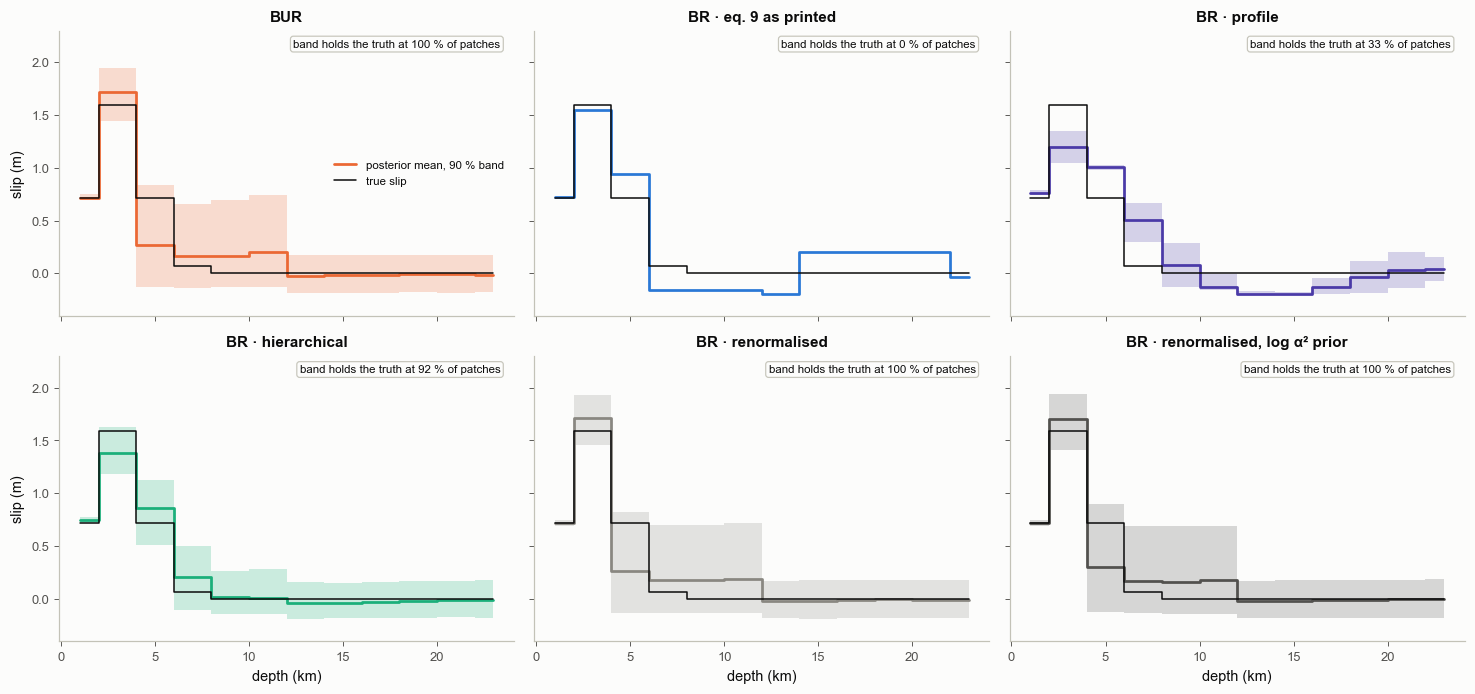

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(13.5, 6.4), sharex=True, sharey=True)
for ax, k in zip(axs.ravel(), METHODS):
    r = res0[k]
    ax.fill_between(zc, r["lo"], r["hi"], color=MCOL[k], alpha=0.22, lw=0, step="mid")
    ax.step(zc, r["mean"], where="mid", color=MCOL[k], lw=1.8, label="posterior mean, 90 % band")
    ax.step(zc, s_true, where="mid", color=C_TRUE, lw=1.0, label="true slip")
    ax.set_ylim(-0.4, 2.3)
    ax.set_title(k, fontsize=10)
    S.badge(ax, f"band holds the truth at {metrics(r, s_true)['cov'] * 100:.0f} % of patches", loc="upper right", fs=7.5)
for ax in axs[1]:
    ax.set_xlabel("depth (km)")
for ax in axs[:, 0]:
    ax.set_ylabel("slip (m)")
axs[0, 0].legend(fontsize=7.5, loc="center right")
fig.tight_layout()
bk.savefig(fig, "2-31_methods_one_case")
plt.show()

**How to read it.** Black: true slip; coloured line and band: posterior mean and central 90 % interval; the badge
counts the patches whose band contains the truth (12 patches).
* **BUR** follows the patch where the data resolve it; below about 6 km its band spans most of the bounds and its
  mean drifts toward their middle.
* **eq. 9 as printed** has no band at all: its α² sits at the top of the range (next figure), so every "posterior"
  model is the same bounded least-squares fit.
* **profile** smooths more and its band is only the spread of optimal models across α²; it misses the truth at most
  patches.
* **hierarchical** smooths too, but its band includes the slip uncertainty at each α².
* **renormalised** looks like BUR, and the next figure shows why.

saved figures/2-31_alpha_and_bounds.png


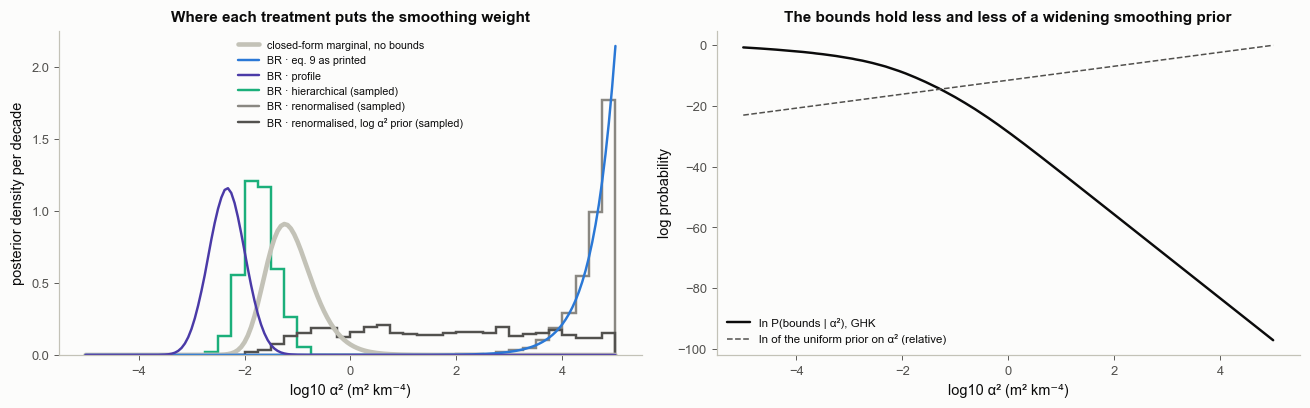

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
per_dec = (LA[1] - LA[0]) / np.log(10)
lml = np.array([log_marginal(d0, sig0, a2) for a2 in A2])
wm = np.exp(lml - lml.max()) * A2
axs[0].plot(np.log10(A2), wm / wm.sum() / per_dec, color=S.AXIS, lw=3.0, label="closed-form marginal, no bounds")
for k in [EQ9, PROF]:
    axs[0].plot(np.log10(A2), res0[k]["w"] / per_dec, color=MCOL[k], lw=1.6, label=k)
for k in [HIER, REN, RENLOG]:
    h, edges = np.histogram(res0[k]["la2"] / np.log(10), bins=np.arange(-5, 5.01, 0.25), density=True)
    axs[0].stairs(h, edges, color=MCOL[k], lw=1.6, label=k + " (sampled)")
axs[0].set_xlabel("log10 α² (m² km⁻⁴)")
axs[0].set_ylabel("posterior density per decade")
axs[0].set_title("Where each treatment puts the smoothing weight", fontsize=10)
axs[0].legend(fontsize=7, loc="upper center")
axs[1].plot(np.log10(A2), LPB, color=S.INK, lw=1.6, label="ln P(bounds | α²), GHK")
axs[1].plot(np.log10(A2), LA - LA[-1], color=S.INK2, lw=1.0, ls="--", label="ln of the uniform prior on α² (relative)")
axs[1].set_xlabel("log10 α² (m² km⁻⁴)")
axs[1].set_ylabel("log probability")
axs[1].set_title("The bounds hold less and less of a widening smoothing prior", fontsize=10)
axs[1].legend(fontsize=7.5, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-31_alpha_and_bounds")
plt.show()

**How to read it.** Left: posterior of the smoothing weight (large α² = weak smoothing). The grey band is the
closed-form marginal without bounds, a check on the hierarchical sampler. Right: the probability that the unbounded
smoothing prior lands inside the bounds (solid) and the uniform hyperprior on α² (dashed), both on a log scale.
* Eq. 9 as printed piles up at the top: nothing in it rewards smoothing except the roughness term, which always
  prefers less.
* Without renormalisation (profile, hierarchical), the solid curve acts as an extra prior that drags α² down.
* Renormalised, the dashed curve wins: the uniform prior on α² puts almost all its mass at the top of a range that
  spans ten decades, and at large α² the renormalised smoothing prior is flat inside the bounds. That is the BUR
  prior. **BUR is the weak-smoothing end of a properly normalised BR**, so a hierarchical BR with this hyperprior
  becomes BUR unless the data insist on smoothing.
* With a uniform prior on ln α², the evidence decides; the printed median shows where it lands for these data.

**Worked example.** At the hierarchical median α², the cell below prints each term of the marginal log likelihood
(no bounds), and then the normalisation and determinant terms across the range.

In [7]:
a2w = res0[HIER]["a2"]
A = DtD / a2w + G.T @ G / sig0 ** 2
mbar = np.linalg.solve(A, G.T @ d0 / sig0 ** 2)
terms = {"-chi^2/2": -0.5 * np.sum(((d0 - G @ mbar) / sig0) ** 2),
         "-|D m|^2/(2 a2)": -0.5 * np.sum((Dop @ mbar) ** 2) / a2w,
         "-(N_m/2) ln a2 + (1/2) ln|D'D|": -0.5 * M * np.log(a2w) + 0.5 * logdetDtD,
         "-(1/2) ln|G'C_d^-1 G + D'D/a2|": -0.5 * np.linalg.slogdet(A)[1]}
print(f"alpha^2 = {a2w:.3g}")
for k, v in terms.items():
    print(f"  {k:34s} {v:10.2f}")
vals = list(terms.values())
print(f"  {'eq. 9 as printed (first two)':34s} {vals[0] + vals[1]:10.2f}")
print(f"  {'profile (first three)':34s} {sum(vals[:3]):10.2f}")
print(f"  {'marginal (all four, + const)':34s} {sum(vals):10.2f}")
for a2t in [1e-5, 1e-3, 1e-1, 1e1, 1e3, 1e5]:
    At = DtD / a2t + G.T @ G / sig0 ** 2
    nrm, det = -0.5 * M * np.log(a2t) + 0.5 * logdetDtD, -0.5 * np.linalg.slogdet(At)[1]
    print(f"alpha^2 = {a2t:7.0e}: normalisation {nrm:8.2f}, determinant term {det:8.2f}, sum {nrm + det:8.2f}")

alpha^2 = 0.0184
  -chi^2/2                               -17.14
  -|D m|^2/(2 a2)                         -2.72
  -(N_m/2) ln a2 + (1/2) ln|D'D|           7.32
  -(1/2) ln|G'C_d^-1 G + D'D/a2|         -23.73
  eq. 9 as printed (first two)           -19.85
  profile (first three)                  -12.53
  marginal (all four, + const)           -36.26
alpha^2 =   1e-05: normalisation    52.44, determinant term   -57.81, sum    -5.37
alpha^2 =   1e-03: normalisation    24.81, determinant term   -36.02, sum   -11.21
alpha^2 =   1e-01: normalisation    -2.82, determinant term   -17.14, sum   -19.96
alpha^2 =   1e+01: normalisation   -30.45, determinant term    -1.20, sum   -31.65
alpha^2 =   1e+03: normalisation   -58.08, determinant term    11.97, sum   -46.11
alpha^2 =   1e+05: normalisation   -85.71, determinant term    22.55, sum   -63.16


The last six lines are the profile mechanism. As α² shrinks, the normalisation term grows without limit (it rewards
strong smoothing) while the determinant term falls by almost as much, so their sum levels off. A score without the
determinant term keeps the reward and loses the brake; a score with neither has only the roughness penalty, which
always prefers weaker smoothing.

### The Test 1 analogue across noise levels, with noise-free and noisy data

Zhao & Jiang's Test 1 varies σ_d from 0.5 to 5 cm. They report peak posterior-mean slip of 1.67, 1.62, 1.38 and 1.38 m
for BUR and 1.31, 1.14, 0.81 and 0.53 m for BR (true 1.59 m), and "With higher data variances, BR regularization
strengthens (α2 reaching the lower prior bound)" (p. 8). Their data are noise-free: "Noise‐free synthetic surface
displacements in three components are generated and used in inversions [...] using a Cd with only diagonal
variances" (pp. 7-8). We run the same four noise levels with noise-free data and with 3 noisy realisations each.
BR · renormalised with the uniform α² prior is left out: it matched BUR above, for a reason that holds at every noise
level.

In [8]:
SIGS = [0.5, 1.0, 2.0, 5.0]
R_NOISY = 3
NOISY = range(1, R_NOISY + 1)
SWEEP_M = [BUR, EQ9, PROF, HIER, RENLOG]
sweep = {}
for sig in SIGS:
    for rep in range(R_NOISY + 1):                                   # rep 0 = noise-free
        noise = 0.0 if rep == 0 else sig * np.random.default_rng(100 * rep + int(10 * sig)).standard_normal(Nd)
        res = run(G @ s_true + noise, sig, SWEEP_M, seed=10 * rep + int(10 * sig))
        for k in SWEEP_M:
            sweep[(sig, rep, k)] = dict(metrics(res[k], s_true), a2=res[k].get("a2", np.nan))
avg = lambda sig, reps, k, q: np.mean([sweep[(sig, r, k)][q] for r in reps])
print(f"sigma_d (cm):{'':27s}" + "".join(f"{s:>8}" for s in SIGS) + "   " + "".join(f"{s:>8}" for s in SIGS))
for q, lab in [("peak", f"peak of the mean (m), true {s_true.max():.2f}"), ("rmse", "rms error (m)"),
               ("rough", f"roughness (m/km), true {rough(s_true):.3f}"), ("cov", "90 % coverage"), ("a2", "median alpha^2")]:
    print(lab + "    [noise-free | mean of noisy]")
    for k in SWEEP_M:
        if q == "a2" and k == BUR:
            continue
        print(f"  {k:36s} " + "".join(f"{avg(s, [0], k, q):8.3g}" for s in SIGS) + " | "
              + "".join(f"{avg(s, NOISY, k, q):8.3g}" for s in SIGS))

sigma_d (cm):                                0.5     1.0     2.0     5.0        0.5     1.0     2.0     5.0
peak of the mean (m), true 1.59    [noise-free | mean of noisy]
  BUR                                      1.69    1.71    1.65    1.32 |     1.69    1.72    1.65    1.08
  BR · eq. 9 as printed                    1.59    1.59    1.59    1.59 |     1.61    1.85    1.63     1.9
  BR · profile                             1.42    1.17   0.838   0.833 |     1.43    1.14   0.849   0.825
  BR · hierarchical                        1.51    1.36    1.07   0.841 |     1.52    1.34    1.09   0.849
  BR · renormalised, log α² prior          1.66    1.67    1.59    1.06 |     1.68    1.69    1.57   0.973
rms error (m)    [noise-free | mean of noisy]
  BUR                                     0.127    0.15   0.151   0.205 |    0.129    0.19   0.161    0.29
  BR · eq. 9 as printed                 0.00945  0.0109  0.0141  0.0194 |      0.3    0.44   0.244   0.518
  BR · profile                   

saved figures/2-31_test1_sweep.png


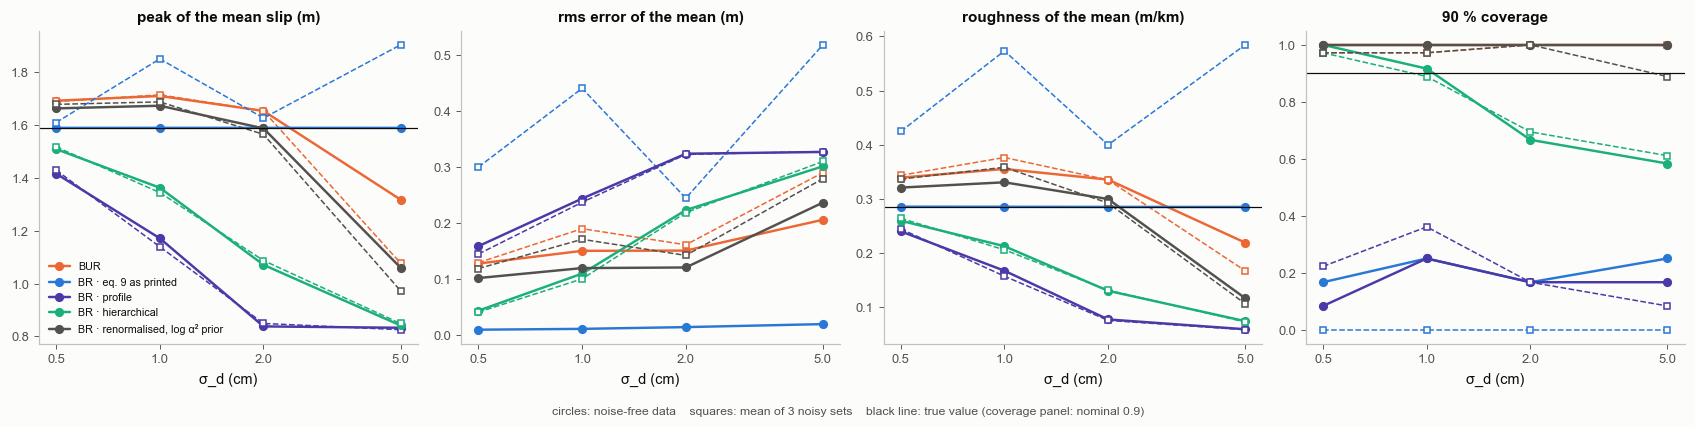

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(15.5, 3.7))
for ax, (q, lab) in zip(axs, [("peak", "peak of the mean slip (m)"), ("rmse", "rms error of the mean (m)"),
                             ("rough", "roughness of the mean (m/km)"), ("cov", "90 % coverage")]):
    for k in SWEEP_M:
        ax.plot(SIGS, [avg(s, [0], k, q) for s in SIGS], "o-", color=MCOL[k], lw=1.6, ms=5, label=k if q == "peak" else None)
        ax.plot(SIGS, [avg(s, NOISY, k, q) for s in SIGS], "s--", color=MCOL[k], lw=1.0, ms=4, mfc=S.SURFACE)
    ref = {"peak": s_true.max(), "rough": rough(s_true), "cov": 0.9}.get(q)
    if ref is not None:
        ax.axhline(ref, color=C_TRUE, lw=0.8)
    ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(SIGS); ax.set_xticklabels([str(s) for s in SIGS])
    ax.set_xlabel("σ_d (cm)"); ax.set_title(lab, fontsize=10)
axs[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.text(0.5, -0.03, "circles: noise-free data    squares: mean of 3 noisy sets    black line: true value (coverage panel: nominal 0.9)",
         ha="center", fontsize=8, color=S.INK2)
bk.savefig(fig, "2-31_test1_sweep")
plt.show()

**How to read it** (numbers in the table above; circles noise-free, squares noisy).
* **Peak loss with noise is smoothing, not only the shortcut.** The hierarchical BR also loses peak as σ_d grows,
  because noisier data support less detail and the evidence then prefers smoother models; the profile follows a
  similar path. Zhao & Jiang's BR trend is therefore what a Laplacian prior does with noisy data, whether or not their
  implementation profiles α².
* **The profile's cost is the uncertainty.** Its coverage stays far below 0.9 at every noise level, because the spread
  of optimal models across α² ignores the slip uncertainty at fixed α². This matches their remark that "BR uncertainty
  can be unrealistically narrowed by strong smoothing constraints rather than data" (p. 11).
* **Noise-free data flatter optimisation, not posterior means.** Eq. 9 as printed (in effect bounded least squares)
  recovers the noise-free truth almost exactly and is worst on noisy data. The posterior means of BUR and of the
  hierarchical BR change much less between noise-free and noisy data.
* **BUR** keeps the peak until the highest noise level, and its band covers the truth.

**What this does and does not show.** Whether Zhao & Jiang's BR includes the normalising factor, and whether it
profiles or integrates, is in their Supporting Information (Text S1), which we have not read. In our toy the answer
changes the uncertainty much more than the mean. This is toy evidence, not a finding about their code.

### Where BUR wins and where BR wins

Three sharper truths in the resolved zone, two noise levels, 3 noisy realisations each. Scores: rms error of the
posterior mean in the resolved zone (0-6 km) and below it (6-24 km), and the roughness of the mean divided by the true
roughness (1 = the right amount of detail).

In [10]:
CASES = ["sharp step at 4 km", "two shallow asperities", "rough random (T3.1 analogue)"]
SIG2 = [0.5, 2.0]
WIN_M = [BUR, PROF, HIER, RENLOG]
win = {}
for ci, name in enumerate(CASES):
    st = TRUTHS[name]
    for sig in SIG2:
        for rep in NOISY:
            d = G @ st + sig * np.random.default_rng(7000 + 100 * rep + int(10 * sig) + ci).standard_normal(Nd)
            res = run(d, sig, WIN_M, seed=500 + 10 * rep + ci)
            for k in WIN_M:
                win[(name, sig, rep, k)] = metrics(res[k], st)
wavg = lambda name, sig, k, q: np.mean([win[(name, sig, r, k)][q] for r in NOISY])
for name in CASES:
    for sig in SIG2:
        print(f"{name}, sigma_d {sig} cm")
        for k in WIN_M:
            print(f"   {k:32s} rmse 0-6 km {wavg(name, sig, k, 'rmse_sh'):.3f}, 6-24 km {wavg(name, sig, k, 'rmse_dp'):.3f}; "
                  f"roughness / true {wavg(name, sig, k, 'rough_ratio'):.2f}; coverage {wavg(name, sig, k, 'cov'):.2f}")

sharp step at 4 km, sigma_d 0.5 cm
   BUR                              rmse 0-6 km 0.024, 6-24 km 0.032; roughness / true 0.98; coverage 1.00
   BR · profile                     rmse 0-6 km 0.356, 6-24 km 0.120; roughness / true 0.63; coverage 0.14
   BR · hierarchical                rmse 0-6 km 0.268, 6-24 km 0.043; roughness / true 0.67; coverage 0.75
   BR · renormalised, log α² prior  rmse 0-6 km 0.071, 6-24 km 0.024; roughness / true 0.89; coverage 0.97
sharp step at 4 km, sigma_d 2.0 cm
   BUR                              rmse 0-6 km 0.113, 6-24 km 0.055; roughness / true 0.84; coverage 1.00
   BR · profile                     rmse 0-6 km 0.446, 6-24 km 0.169; roughness / true 0.52; coverage 0.14
   BR · hierarchical                rmse 0-6 km 0.388, 6-24 km 0.065; roughness / true 0.55; coverage 0.83
   BR · renormalised, log α² prior  rmse 0-6 km 0.279, 6-24 km 0.045; roughness / true 0.63; coverage 0.97
two shallow asperities, sigma_d 0.5 cm
   BUR                             

saved figures/2-31_where_bur_wins.png


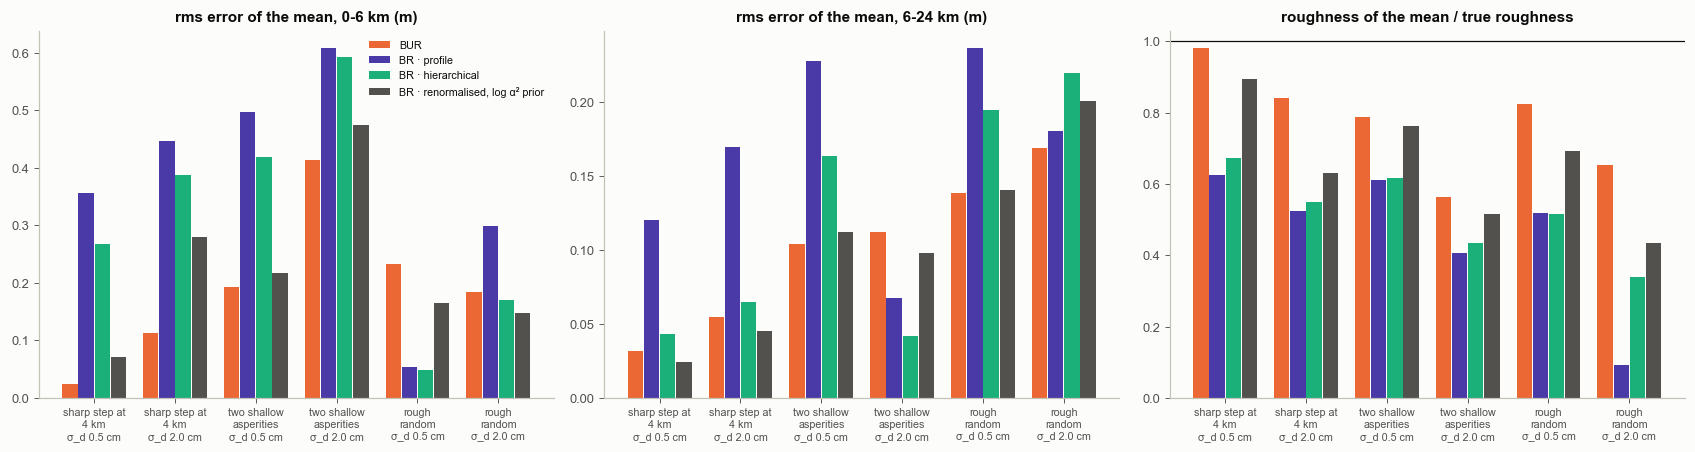

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.2))
xpos = np.arange(len(CASES) * len(SIG2))
brk = lambda n: n.split(" (")[0].replace("at ", "at\n").replace("shallow ", "shallow\n").replace("rough ", "rough\n")
labels = [brk(n) + f"\nσ_d {s} cm" for n in CASES for s in SIG2]   # break the case names so neighbouring labels do not collide
for j, k in enumerate(WIN_M):
    for ax, q in zip(axs, ["rmse_sh", "rmse_dp", "rough_ratio"]):
        ax.bar(xpos + (j - 1.5) * 0.2, [wavg(n, s, k, q) for n in CASES for s in SIG2], width=0.19, color=MCOL[k],
               label=k if q == "rmse_sh" else None)
axs[2].axhline(1.0, color=C_TRUE, lw=0.8)
for ax, t in zip(axs, ["rms error of the mean, 0-6 km (m)", "rms error of the mean, 6-24 km (m)",
                       "roughness of the mean / true roughness"]):
    ax.set_xticks(xpos); ax.set_xticklabels(labels, fontsize=7); ax.set_title(t, fontsize=10)
axs[0].legend(fontsize=7)
fig.tight_layout()
bk.savefig(fig, "2-31_where_bur_wins")
plt.show()

**How to read it.** Bars are means over 3 noisy data sets (coverage in the table above).
* **Roughness** (right): the smoothing variants return less roughness than the truth has, and BUR comes closest, which
  is Zhao & Jiang's central claim: "RMS roughness is consistently better recovered by BUR (Figure 5a), while BR always
  underestimates slip roughness" (p. 10).
* **Error in the resolved zone** (left): for sharp truths BUR's mean is closer to the truth than the smoothed means.
* **Error below 6 km** (middle): here the data say little and the comparison is about priors. BUR's mean is pulled
  toward the middle of its bounds, which Zhao & Jiang also see ("spurious non‐zero mean slip at intermediate depths
  (8–16 km) from broad posteriors", p. 8).

**Common misreadings.**
* "Lower rms error means a more faithful model." A smooth mean can have a small rms error and still erase the edges
  that matter physically (section 3).
* "Roughness of the BUR mean is real structure." Only where the data resolve the patches; Zhao & Jiang compute roughness
  on the posterior mean because "sample‐level roughness primarily reflects intra‐parameter trade‐offs rather than
  physical characteristics" (p. 7).

## 3. Does smoothing manufacture overlap between slip modes?

**In plain words.** If coseismic slip and afterslip occupy neighbouring patches with a sharp boundary, a smoothing
prior spreads each one across the boundary, so the two models appear to share fault area. For Ridgecrest, Zhao & Jiang
find BR overlapping moments of "∼ 30% and 60% for thresholds at 0.2 and 0.1, respectively, nearly twice the
corresponding BUR estimates" (p. 18).

**Precisely (our 1-D version of their metric).** For a threshold $t$, the overlap patches are those where both
posterior-mean models exceed $t$ times their own peak; the *shared moment* is $\sum_{i\in\text{overlap}}\min(\hat c_i,\hat p_i)$,
with $\hat c$, $\hat p$ the two profiles normalised to unit sum (0 = disjoint, 1 = identical). Their exact definition
may differ in detail.

Design: coseismic slip 1.5 m on 0-4 km and afterslip 0.4 m on 4-8 km, so the true shared moment is zero and the
boundary lies where our toy can resolve it; σ_d = 1 cm (coseismic) and 0.3 cm (postseismic); $s_m$ = 2 m and 0.5 m.

In [12]:
co_true = np.where(zc < 4, 1.5, 0.0)
post_true = np.where((zc > 4) & (zc < 8), 0.4, 0.0)
SIG_CO, SIG_POST = 1.0, 0.3
lb_p, ub_p = bounds(0.5)
LPB_P = log_pbounds(lb_p, ub_p)
OV_M = [BUR, PROF, HIER, RENLOG]


def shared_moment(a, b, t):
    a, b = np.maximum(a, 0), np.maximum(b, 0)
    both = (a >= t * a.max()) & (b >= t * b.max())
    return float(np.sum(np.minimum(a / a.sum(), b / b.sum())[both]))


ovl = {k: {0.1: [], 0.2: []} for k in OV_M}
show_ov = {}
for rep in range(6):
    rr = np.random.default_rng(900 + rep)
    dc = G @ co_true + SIG_CO * rr.standard_normal(Nd)
    dp = G @ post_true + SIG_POST * rr.standard_normal(Nd)
    rc = run(dc, SIG_CO, OV_M, seed=2000 + rep)
    rp = run(dp, SIG_POST, OV_M, lo=lb_p, hi=ub_p, lpb=LPB_P, seed=3000 + rep)
    for k in OV_M:
        for t in (0.1, 0.2):
            ovl[k][t].append(shared_moment(rc[k]["mean"], rp[k]["mean"], t))
        if rep == 0:
            show_ov[k] = (rc[k]["mean"], rp[k]["mean"])
for t in (0.1, 0.2):
    print(f"threshold {t}: true {shared_moment(co_true, post_true, t):.2f}; " + "; ".join(
        f"{k} {np.mean(ovl[k][t]):.2f} (range {np.min(ovl[k][t]):.2f}-{np.max(ovl[k][t]):.2f})" for k in OV_M))

threshold 0.1: true 0.00; BUR 0.08 (range 0.03-0.15); BR · profile 0.30 (range 0.26-0.35); BR · hierarchical 0.25 (range 0.23-0.27); BR · renormalised, log α² prior 0.14 (range 0.10-0.22)
threshold 0.2: true 0.00; BUR 0.04 (range 0.00-0.09); BR · profile 0.27 (range 0.25-0.28); BR · hierarchical 0.25 (range 0.23-0.27); BR · renormalised, log α² prior 0.06 (range 0.00-0.22)


saved figures/2-31_overlap.png


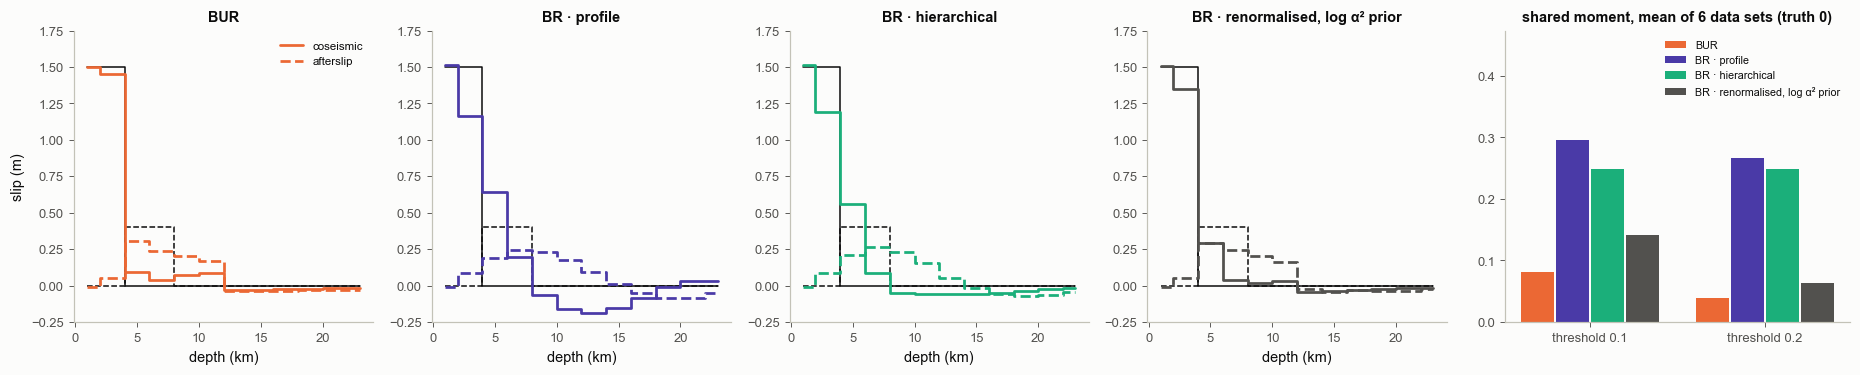

In [13]:
fig, axs = plt.subplots(1, 5, figsize=(17, 3.5), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.15]))
for ax, k in zip(axs[:4], OV_M):
    mc_, mp_ = show_ov[k]
    ax.step(zc, co_true, where="mid", color=C_TRUE, lw=1.0)
    ax.step(zc, post_true, where="mid", color=C_TRUE, lw=1.0, ls="--")
    ax.step(zc, mc_, where="mid", color=MCOL[k], lw=1.8, label="coseismic")
    ax.step(zc, mp_, where="mid", color=MCOL[k], lw=1.8, ls="--", label="afterslip")
    ax.set_ylim(-0.25, 1.75)
    ax.set_title(k, fontsize=9.5); ax.set_xlabel("depth (km)")
axs[0].set_ylabel("slip (m)")
axs[0].legend(fontsize=7.5, loc="upper right")
ax = axs[4]
for j, k in enumerate(OV_M):
    ax.bar(np.arange(2) + (j - 1.5) * 0.2, [np.mean(ovl[k][t]) for t in (0.1, 0.2)], width=0.19, color=MCOL[k], label=k)
ax.set_xticks([0, 1]); ax.set_xticklabels(["threshold 0.1", "threshold 0.2"])
ax.set_title("shared moment, mean of 6 data sets (truth 0)", fontsize=9.5)
ax.set_ylim(0, 1.6 * max(np.mean(ovl[k][t]) for k in OV_M for t in (0.1, 0.2)))   # headroom for the legend
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-31_overlap")
plt.show()

**How to read it.** Black: the true coseismic slip (solid) and afterslip (dashed), which share no patch. Coloured: one
realisation's posterior means. The bars average 6 realisations. The smoothing variants spread both models across the
4-km boundary, so the shared moment grows; the printed numbers say by how much in this toy. Overlap measured on
smoothed models is therefore partly a property of the prior, which matters for any claim about whether afterslip
invades the coseismic rupture.

**In practice.** Joint inversions that estimate coseismic slip and afterslip together often ask whether afterslip
overlaps the coseismic rupture; that overlap is exactly the quantity a smoothing prior can inflate.

## 4. Smoothing after sampling, not before (Jiang & Simons 2016)

**In plain words.** Instead of building smoothness into the prior, sample with a weak prior and then average the
posterior samples over a chosen length. Each averaged quantity has its own posterior; averages over several patches
are well determined even when single patches are not. Jiang & Simons chose their prior "With minimal a priori
assumptions on the spatial correlations of model parameters (e.g., smoothness)" (p. 9057), and averaged afterwards:
the subsequent spatial smoothing "effectively allows us to focus on model features for certain length scales [...]
avoiding the need to choose between model complexity and data fit" (p. 9061).

**Precisely.** For a window of $k$ patches, the averaged slip is $\bar m^{(k)}_i = \frac1k\sum_{j\in w_i} m_j$;
applying it to every posterior sample gives samples of $\bar m^{(k)}$. Its posterior sd falls with $k$ faster than
$1/\sqrt k$ when neighbouring patches trade off (negative posterior correlation), because averaging cancels the
trade-off.

In [14]:
s4 = TRUTHS["two shallow asperities"]
K_WIN = [1, 2, 4, 8]


def window_avg(X, k):
    """Moving average over k patches; at the ends the window is shifted inward so it always holds k patches."""
    out = np.empty_like(X)
    for i in range(M):
        a = min(max(0, i - k // 2), M - k)
        out[..., i] = X[..., a:a + k].mean(-1)
    return out


cov4 = {k: [] for k in K_WIN}
cov4_br = {HIER: [], RENLOG: []}
sd4 = {k: [] for k in K_WIN}
for rep in range(12):
    d = G @ s4 + 1.0 * np.random.default_rng(4000 + rep).standard_normal(Nd)
    rr_ = run(d, 1.0, [BUR, HIER, RENLOG] if rep < 6 else [BUR], seed=4000 + rep)
    for k in K_WIN:
        Sk, tk = window_avg(rr_[BUR]["S"], k), window_avg(s4[None], k)[0]
        lo, hi = np.percentile(Sk, [5, 95], axis=0)
        cov4[k].append(np.mean((tk >= lo) & (tk <= hi)))
        sd4[k].append(Sk.std(0))
    for k in cov4_br:
        if k in rr_:
            cov4_br[k].append(metrics(rr_[k], s4)["cov"])
pl = lambda k: f"{k} patch{'es' if k > 1 else ''}"
print("BUR, 90 % coverage of the equally averaged truth (12 data sets): "
      + ", ".join(f"{pl(k)} {np.mean(cov4[k]):.2f}" for k in K_WIN))
print("smoothing priors, unaveraged (6 data sets): " + ", ".join(f"{k} {np.mean(v):.2f}" for k, v in cov4_br.items()))
print("BUR posterior sd, mean over patches and data sets: " + ", ".join(f"{pl(k)} {np.mean(sd4[k]):.3f} m" for k in K_WIN)
      + f"; 1/sqrt(k) from {pl(1)} would give " + ", ".join(f"{np.mean(sd4[1]) / np.sqrt(k):.3f}" for k in K_WIN))

BUR, 90 % coverage of the equally averaged truth (12 data sets): 1 patch 0.91, 2 patches 0.88, 4 patches 0.94, 8 patches 0.96
smoothing priors, unaveraged (6 data sets): BR · hierarchical 0.76, BR · renormalised, log α² prior 0.88
BUR posterior sd, mean over patches and data sets: 1 patch 0.172 m, 2 patches 0.109 m, 4 patches 0.063 m, 8 patches 0.030 m; 1/sqrt(k) from 1 patch would give 0.172, 0.121, 0.086, 0.061


saved figures/2-31_posterior_averaging.png


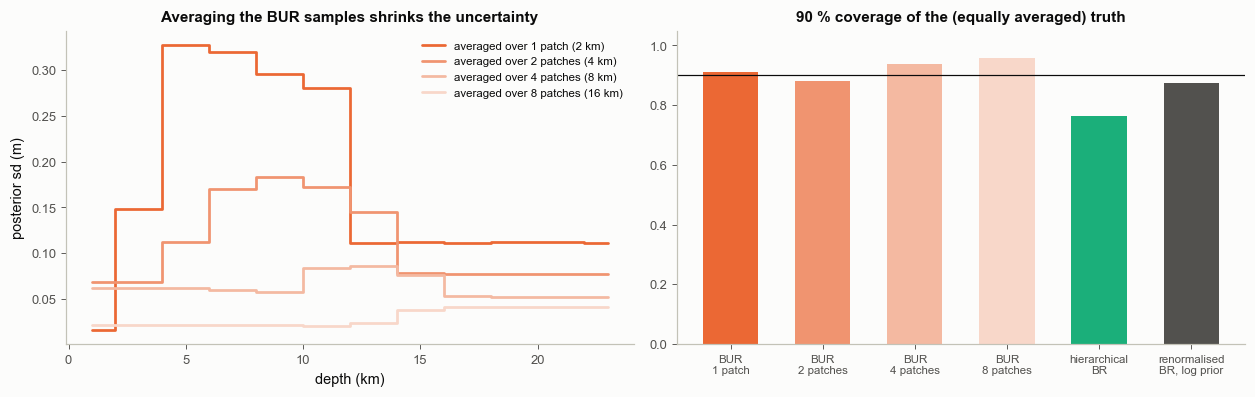

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.7))
from matplotlib.colors import to_rgb
cols4 = [tuple(f * np.array(to_rgb(S.ORANGE)) + (1 - f) * np.array(to_rgb(S.SURFACE))) for f in (1.0, 0.7, 0.45, 0.25)]   # BUR: orange shades
for k, c in zip(K_WIN, cols4):
    axs[0].step(zc, np.mean(sd4[k], axis=0), where="mid", color=c, lw=1.8, label=f"averaged over {pl(k)} ({k * LF:.0f} km)")
axs[0].set_xlabel("depth (km)"); axs[0].set_ylabel("posterior sd (m)")
axs[0].set_title("Averaging the BUR samples shrinks the uncertainty", fontsize=10)
axs[0].legend(fontsize=7.5)
labs = [f"BUR\n{pl(k)}" for k in K_WIN] + ["hierarchical\nBR", "renormalised\nBR, log prior"]
vals = [np.mean(cov4[k]) for k in K_WIN] + [np.mean(cov4_br[HIER]), np.mean(cov4_br[RENLOG])]
axs[1].bar(labs, vals, color=cols4 + [MCOL[HIER], MCOL[RENLOG]], width=0.6)
axs[1].axhline(0.9, color=C_TRUE, lw=0.8)
axs[1].set_ylim(0, 1.05)
axs[1].tick_params(axis="x", labelsize=7.5)
axs[1].set_title("90 % coverage of the (equally averaged) truth", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-31_posterior_averaging")
plt.show()

**How to read it.** Left: the posterior sd of BUR slip averaged over 1, 2, 4 and 8 patches. Right: how often the 90 %
interval of each average contains the truth averaged the same way, next to the unaveraged smoothing priors. Averaging
after sampling keeps the full-resolution ensemble: you can read single patches where the data resolve them and
8-patch averages where they do not, each with its own uncertainty. A smoothing prior makes that choice once, before
the data, and its posterior cannot be un-smoothed afterwards.

**Common misreadings.** "Averaging after sampling is the same as smoothing before." The mean of a BR posterior is
shaped by the prior everywhere, including where the data would have resolved sharp detail; an averaged BUR posterior is
shaped by the data and by a length the reader can see and change.

## 5. Model error in an unregularised inversion: $C_\chi = C_d + C_p$

**In plain words.** Without a smoothing prior, nothing stops the inversion from bending slip to fit what is really an
error in the physics (a slightly wrong elastic structure or fault depth). $C_p$ is the covariance of that prediction
error: it tells the inversion which data the model cannot predict exactly, and by how much. Jiang & Simons: "Cp is
generally expected to approximately scale with the model and is usually ignored or underestimated. For large-amplitude
observations, the variances of Cp can overwhelm those of Cd" (p. 9055). Both papers recompute $C_p$ from the current
model. Jiang & Simons write "in later iterations we update $C_p^{HB}$ to be consistent with previously obtained
posterior mean solution" (p. 9057), and Zhao & Jiang "compute Cp using the model ensemble mean during each tempering
step" (p. 6). (Tempering: the data are switched on gradually; reminder: 2.20.)

**Precisely.** With an uncertain structural parameter θ (here a depth scale, $\theta\sim\mathcal N(0,\sigma_\theta^2)$) and
predictions $\mathbf G(\theta)\mathbf m$, the first-order prediction error is $\mathbf k_\theta\,\delta\theta$ with
$\mathbf k_\theta = \partial[\mathbf G(\theta)\mathbf m]/\partial\theta$ (the sensitivity of the predictions to θ; reminder: 2.13
and 2.22), so $C_p = \sigma_\theta^2\,\mathbf k_\theta\mathbf k_\theta^\top$
(Duputel et al. 2014). Because $\mathbf k_\theta$ is proportional to $\mathbf m$, $C_p$ grows with the slip.

Test: each data set is generated with its own true depth scale $1+\theta$, $\theta\sim\mathcal N(0, 0.12^2)$, plus noise
σ_d = 0.5 cm; the inversion always uses the nominal Green's functions. BUR with $C_d$ only is compared with BUR with
$C_d + C_p$: $C_p$ first from the $C_d$-only ensemble mean, then once more from the new ensemble mean, and, as the
ideal, from the true slip. Calibration score: the mean of $z^2 = (\bar m_j - m_j^{\rm true})^2/\mathrm{sd}_j^2$ over the
resolved patches, which is about 1 for honest uncertainties.

In [16]:
SIG_TH, SIG5 = 0.12, 0.5
s5 = TRUTHS["Gaussian patch (Test 1 analogue)"]
k_of = lambda m: (greens(1 + 1e-4) @ m - greens(1 - 1e-4) @ m) / 2e-4     # sensitivity of predictions to the depth scale
Cd = SIG5 ** 2 * np.eye(Nd)
chol_chi = lambda m: np.linalg.cholesky(Cd + SIG_TH ** 2 * np.outer(k_of(m), k_of(m)))
CP_RUNS = ["C_d only", "C_d + C_p, from the C_d-only mean", "C_d + C_p, updated once", "C_d + C_p at the true slip"]
cal = {k: dict(cov=[], cov_sh=[], z2=[], rmse=[]) for k in CP_RUNS}
show5 = None
for rep in range(12):
    rr = np.random.default_rng(6000 + rep)
    th = SIG_TH * rr.standard_normal()
    d = greens(1 + th) @ s5 + SIG5 * rr.standard_normal(Nd)
    Sx = {CP_RUNS[0]: sample(model_bur, d, SIG5, lb, ub, seed=6000 + rep)["m"]}
    Sx[CP_RUNS[1]] = sample(model_bur_cov, d, chol_chi(Sx[CP_RUNS[0]].mean(0)), lb, ub, seed=6100 + rep)["m"]
    Sx[CP_RUNS[2]] = sample(model_bur_cov, d, chol_chi(Sx[CP_RUNS[1]].mean(0)), lb, ub, seed=6200 + rep)["m"]
    Sx[CP_RUNS[3]] = sample(model_bur_cov, d, chol_chi(s5), lb, ub, seed=6300 + rep)["m"]
    for k, X in Sx.items():
        lo, hi = np.percentile(X, [5, 95], axis=0)
        inside = (s5 >= lo) & (s5 <= hi)
        cal[k]["cov"].append(np.mean(inside))
        cal[k]["cov_sh"].append(np.mean(inside[SHALLOW]))
        cal[k]["z2"].append(np.mean(((X.mean(0) - s5) / X.std(0))[SHALLOW] ** 2))
        cal[k]["rmse"].append(np.sqrt(np.mean((X.mean(0) - s5) ** 2)))
    if show5 is None and abs(th) > 0.15:
        show5 = (th, Sx)
for k in CP_RUNS:
    print(f"{k:36s} coverage {np.mean(cal[k]['cov']):.2f} (0-6 km {np.mean(cal[k]['cov_sh']):.2f}), "
          f"mean z^2 (0-6 km) {np.mean(cal[k]['z2']):5.2f}, rmse {np.mean(cal[k]['rmse']):.3f} m")
sd_p1, sd_p2 = SIG_TH * np.abs(k_of(s5)), SIG_TH * np.abs(k_of(2 * s5))
print(f"prediction-error sd: largest {sd_p1.max():.2f} cm for the true slip, {sd_p2.max():.2f} cm for twice the slip; "
      f"measurement sd {SIG5} cm")

C_d only                             coverage 0.87 (0-6 km 0.47), mean z^2 (0-6 km)  9.37, rmse 0.186 m
C_d + C_p, from the C_d-only mean    coverage 0.94 (0-6 km 0.75), mean z^2 (0-6 km)  1.90, rmse 0.152 m
C_d + C_p, updated once              coverage 0.96 (0-6 km 0.83), mean z^2 (0-6 km)  1.72, rmse 0.151 m
C_d + C_p at the true slip           coverage 0.99 (0-6 km 0.94), mean z^2 (0-6 km)  0.99, rmse 0.125 m
prediction-error sd: largest 1.91 cm for the true slip, 3.82 cm for twice the slip; measurement sd 0.5 cm


saved figures/2-31_model_error.png


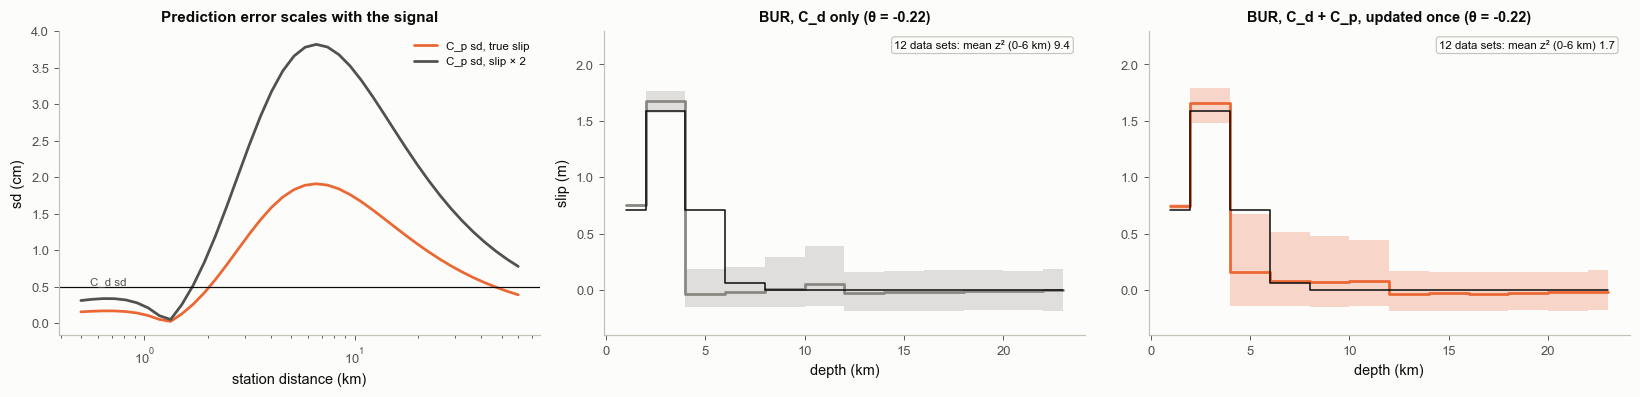

In [17]:
th_s, Sx_s = show5
fig, axs = plt.subplots(1, 3, figsize=(15, 3.7))
axs[0].semilogx(xs, sd_p1, color=S.ORANGE, lw=1.8, label="C_p sd, true slip")
axs[0].semilogx(xs, sd_p2, color=S.INK2, lw=1.8, label="C_p sd, slip × 2")
axs[0].axhline(SIG5, color=C_TRUE, lw=0.8)
axs[0].text(0.55, SIG5 * 1.06, "C_d sd", fontsize=7.5, color=S.INK2)
axs[0].set_xlabel("station distance (km)"); axs[0].set_ylabel("sd (cm)")
axs[0].set_title("Prediction error scales with the signal", fontsize=10)
axs[0].legend(fontsize=7.5)
for ax, k, c in zip(axs[1:], [CP_RUNS[0], CP_RUNS[2]], [S.MUTED, S.ORANGE]):
    X = Sx_s[k]
    lo, hi = np.percentile(X, [5, 95], axis=0)
    ax.fill_between(zc, lo, hi, color=c, alpha=0.25, lw=0, step="mid")
    ax.step(zc, X.mean(0), where="mid", color=c, lw=1.8)
    ax.step(zc, s5, where="mid", color=C_TRUE, lw=1.0)
    ax.set_ylim(-0.4, 2.3); ax.set_xlabel("depth (km)")
    ax.set_title(f"BUR, {k} (θ = {th_s:+.2f})", fontsize=9.5)
    S.badge(ax, f"12 data sets: mean z² (0-6 km) {np.mean(cal[k]['z2']):.1f}", loc="upper right", fs=7.5)
axs[1].set_ylabel("slip (m)")
fig.tight_layout()
bk.savefig(fig, "2-31_model_error")
plt.show()

**How to read it.** Left: the prediction-error sd at each station for the true slip and for twice that slip, against
the measurement sd. It is largest where the signal is largest and doubles when the slip doubles. Middle and right: one
data set generated with a stretched or squeezed structure (θ in the title). With $C_d$ only, the unregularised
inversion is confident about slip that partly reflects the wrong structure; with $C_p$ the bands widen where the
structural error matters. The table above gives the calibration over 12 data sets: $C_p$ brings the mean $z^2$ in the
resolved zone much closer to 1, and the updated $C_p$ comes close to the one computed from the true slip. It does not
make the posterior mean more accurate; it makes its uncertainty honest.

**In practice.** Zhao & Jiang include $C_p$ "that captures uncertainty in layer‐wise shear moduli μ
(uncorrelated 10% variations)" at Ridgecrest (p. 6). An inversion with a diagonal $C_d$ and no $C_p$ leaves structural
error to be absorbed by the slip or by the noise scales; 2.13 showed that a single noise scale σ_k cannot imitate a
correlated $C_p$.

## 6. Is the evidence a fair judge? (prior width and correlations)

**In plain words.** Zhao & Jiang use the log evidence $\ln Z$ as the "primary model selection metric" (p. 6), and for
BUR its prior is uniform on boxes whose width scales with $s_m$: "Tests using sm of 1.2− 2 times larger values yield
nearly identical results" (p. 4). That statement is about slip. The evidence behaves differently: widening a uniform
prior spreads the same prior probability over more volume, so $\ln Z$ falls wherever the data, not the bounds, confine
the slip.

**Precisely.** $\ln Z = \mathbb E_{\rm post}[\ln p(\mathbf d\mid\mathbf m)] - D_{\rm KL}(\text{post}\,\|\,\text{prior})$ (their eq. 12):
the log evidence (reminder: 2.20 and 2.29) is the average fit under the posterior minus the information the data
delivered, measured as the KL divergence of the posterior from the prior (2.28).
For a parameter the data pin down well inside its box, widening the box by a factor $c$ leaves the first term
unchanged and raises the KL term by $\ln c$; with six positive boxes the most $\ln Z$ can fall is $6\ln c$. They
estimate KL per patch and sum: "this formulation estimates aggregated marginal information gain but ignores slip
parameter correlation, likely resulting in an underestimate" (p. 6). The missing part is the *total correlation*
$\sum_j H(m_j) - H(\mathbf m)\ge 0$ (entropy, 2.27): how much the patches' uncertainties overlap, zero only when they
are independent. For a Gaussian it equals $-\tfrac12\ln\det(\text{correlation matrix})$ (correlation matrix, 2.03).

**Worked example.** Two shallow asperities, σ_d = 1 cm, $s_m$ = 2, 3 and 4 m. $\ln Z$ from SMC (sequential Monte
Carlo with tempering, which estimates the evidence as a by-product; 2.20. It is the family Zhao & Jiang use, CATMIP),
3 seeds each; posterior means from NUTS.

In [18]:
s6 = TRUTHS["two shallow asperities"]
d6 = G @ s6 + 1.0 * np.random.default_rng(66).standard_normal(Nd)


class BoxProblem:
    """Uniform-box prior x Gaussian likelihood, in the interface that bayeskit's SMC uses."""

    def __init__(self, lo, hi, d, sig):
        self.lo, self.hi, self.d, self.sig = lo, hi, d, sig

    def sample_prior(self, rng, n):
        return self.lo + (self.hi - self.lo) * rng.uniform(size=(n, M))

    def logprior_batch(self, X):
        X = np.atleast_2d(X)
        return np.where(np.all((X >= self.lo) & (X <= self.hi), axis=1), -np.sum(np.log(self.hi - self.lo)), -np.inf)

    def loglik_batch(self, X):
        r = (self.d[None, :] - np.atleast_2d(X) @ G.T) / self.sig
        return -0.5 * np.sum(r ** 2, axis=1) - Nd * np.log(np.sqrt(2 * np.pi) * self.sig)


rows6 = []
for c in [1.0, 1.5, 2.0]:
    lo_c, hi_c = bounds(2.0 * c)
    zs = [SM.smc(BoxProblem(lo_c, hi_c, d6, 1.0), n=3000, rng=np.random.default_rng(seed), n_mcmc=15, record=False)["logZ"]
          for seed in range(3)]
    Sb = sample(model_bur, d6, 1.0, lo_c, hi_c, seed=66)["m"]
    rows6.append(dict(c=c, lnZ=np.mean(zs), sd=np.std(zs), mean=Sb.mean(0), S=Sb, lo=lo_c, hi=hi_c))
    print(f"s_m = {2.0 * c:.0f} m: ln Z = {np.mean(zs):7.2f} (sd over 3 seeds {np.std(zs):.2f}); largest possible fall "
          f"relative to s_m = 2 m: {np.sum(zc <= 12) * np.log(c):.2f} nats")
r0 = rows6[0]
for r in rows6[1:]:
    dm = np.abs(r["mean"] - r0["mean"])
    print(f"s_m x{r['c']}: ln Z changes by {r['lnZ'] - r0['lnZ']:+.2f}; posterior mean changes by at most "
          f"{dm[SHALLOW].max():.3f} m (0-6 km) and {dm[DEEP].max():.3f} m (6-24 km)")


def entropy_1d(x):
    """Vasicek's m-spacing estimate of the differential entropy of a 1-D sample (nats)."""
    n, xs_ = x.size, np.sort(x)
    m_ = int(round(np.sqrt(n)))
    i = np.arange(n)
    return np.mean(np.log(n / (2 * m_) * (xs_[np.minimum(i + m_, n - 1)] - xs_[np.maximum(i - m_, 0)])))


kl_joint = BoxProblem(r0["lo"], r0["hi"], d6, 1.0).loglik_batch(r0["S"]).mean() - r0["lnZ"]   # eq. 12 rearranged
kl_patch = np.sum(np.log(r0["hi"] - r0["lo"])) - sum(entropy_1d(r0["S"][:, j]) for j in range(M))
tc_gauss = -0.5 * np.linalg.slogdet(np.corrcoef(r0["S"].T))[1]
print(f"KL(posterior || prior), s_m = 2 m: joint {kl_joint:.2f} nats (E[ln L] - ln Z), sum of per-patch KL "
      f"{kl_patch:.2f} nats, difference {kl_joint - kl_patch:.2f}; Gaussian total correlation {tc_gauss:.2f} nats")

s_m = 2 m: ln Z =  -67.65 (sd over 3 seeds 0.17); largest possible fall relative to s_m = 2 m: 0.00 nats


s_m = 3 m: ln Z =  -69.40 (sd over 3 seeds 0.12); largest possible fall relative to s_m = 2 m: 2.43 nats


s_m = 4 m: ln Z =  -70.48 (sd over 3 seeds 0.12); largest possible fall relative to s_m = 2 m: 4.16 nats
s_m x1.5: ln Z changes by -1.74; posterior mean changes by at most 0.070 m (0-6 km) and 0.049 m (6-24 km)
s_m x2.0: ln Z changes by -2.83; posterior mean changes by at most 0.143 m (0-6 km) and 0.097 m (6-24 km)
KL(posterior || prior), s_m = 2 m: joint 11.95 nats (E[ln L] - ln Z), sum of per-patch KL 8.80 nats, difference 3.15; Gaussian total correlation 3.26 nats


saved figures/2-31_evidence_width.png


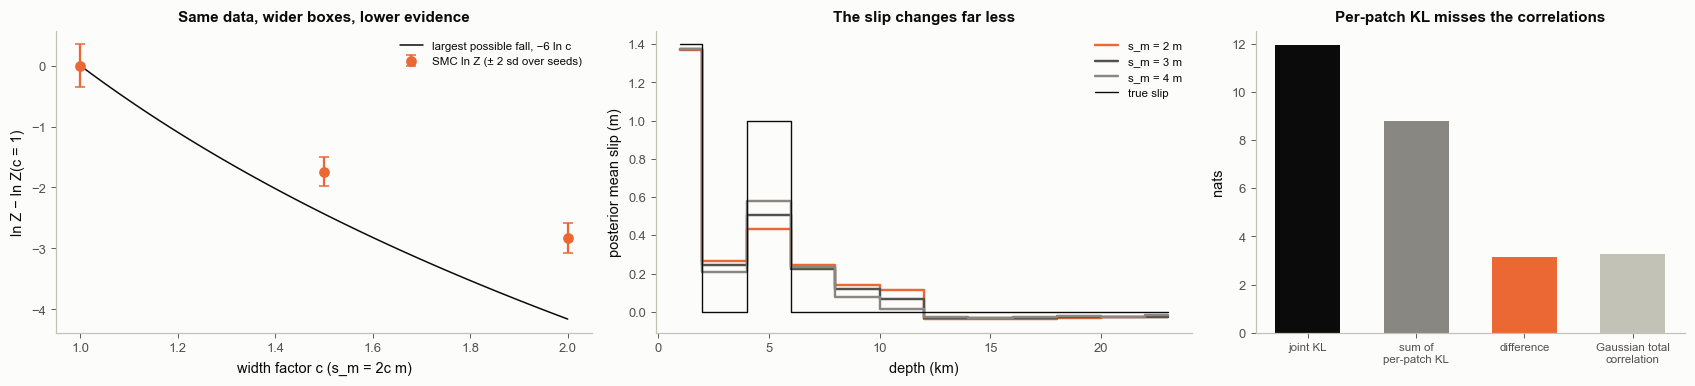

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(15.5, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
cs = [r["c"] for r in rows6]
axs[0].errorbar(cs, [r["lnZ"] - r0["lnZ"] for r in rows6], yerr=[2 * r["sd"] for r in rows6], fmt="o", color=S.ORANGE,
                capsize=3, label="SMC ln Z (± 2 sd over seeds)")
cc = np.linspace(1, 2, 50)
axs[0].plot(cc, -np.sum(zc <= 12) * np.log(cc), color=C_TRUE, lw=1.0, label="largest possible fall, −6 ln c")
axs[0].set_xlabel("width factor c (s_m = 2c m)"); axs[0].set_ylabel("ln Z − ln Z(c = 1)")
axs[0].set_title("Same data, wider boxes, lower evidence", fontsize=10)
axs[0].legend(fontsize=7.5)
for r, col in zip(rows6, [S.ORANGE, S.INK2, S.MUTED]):
    axs[1].step(zc, r["mean"], where="mid", color=col, lw=1.6, label=f"s_m = {2 * r['c']:.0f} m")
axs[1].step(zc, s6, where="mid", color=C_TRUE, lw=0.9, label="true slip")
axs[1].set_xlabel("depth (km)"); axs[1].set_ylabel("posterior mean slip (m)")
axs[1].set_title("The slip changes far less", fontsize=10)
axs[1].legend(fontsize=7.5)
axs[2].bar(["joint KL", "sum of\nper-patch KL", "difference", "Gaussian total\ncorrelation"],
           [kl_joint, kl_patch, kl_joint - kl_patch, tc_gauss], color=[S.INK, S.MUTED, S.ORANGE, S.AXIS], width=0.6)
axs[2].set_ylabel("nats"); axs[2].tick_params(axis="x", labelsize=7.5)
axs[2].set_title("Per-patch KL misses the correlations", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-31_evidence_width")
plt.show()

**How to read it.** Left: widening the shallow boxes lowers $\ln Z$; the black line is the fall if all six shallow
patches were pinned by the data, and the measured fall is smaller because the poorly resolved patches are partly
confined by the bounds themselves. Middle: the posterior mean changes far less, and mostly in the patches the data
resolve least. Right: the sum of per-patch KL divergences is smaller than the joint KL, and the difference matches the
total correlation of a Gaussian with the posterior's correlation matrix. A comparison of BUR and BR by $\ln Z$ therefore
compares prior definitions as much as data fit. The same caution was 2.29's section 5, and it is a reason to compare
runs by WRMS and χ² per data set as well as, or instead of, by log evidence.

A related open point: Zhao & Jiang report that the "BR slip prior, propagated from the hyperparameter prior, is
narrowly constrained to extremely small magnitudes (∼ 10⁻¹⁰ m)" (p. 10). In a hierarchical model the slip prior is the
smoothing prior averaged over the hyperprior. The cell below prints its scale for a uniform α² on [10⁻⁵, 10⁵].

In [20]:
rngp = np.random.default_rng(8)
a2p = rngp.uniform(1e-5, 1e5, 4000)
draws = np.sqrt(a2p)[:, None] * (rngp.standard_normal((4000, M)) @ Ch.T)
print(f"hierarchical prior on slip (uniform alpha^2 on [1e-5, 1e5], before the bounds): median |m| = "
      f"{np.median(np.abs(draws)):.0f} m; draws inside the bounds: {np.sum(np.all((draws >= lb) & (draws <= ub), axis=1))} of 4000")

hierarchical prior on slip (uniform alpha^2 on [1e-5, 1e5], before the bounds): median |m| = 7527 m; draws inside the bounds: 0 of 4000


Before the bounds, this prior is enormous, the opposite of 10⁻¹⁰ m; renormalised inside the bounds it is close to the
BUR prior (section 2). How the hybrid scheme defines its slip prior is not given in the main text, so we note only that
the KL term it produces belongs to that scheme (inference, unverified).

## 7. What "objective" means here

**In plain words.** In this literature "objective" means that no number was tuned by hand after looking at the result.
It never means "free of assumptions". Each approach moves some choices from the analyst to the data and keeps others.

| approach | analyst still chooses | data estimate | assumes |
|---|---|---|---|
| hand-tuned smoothing | form and weight | slip | everything |
| L-curve | form; where the "corner" is (scale-dependent, 2.29) | slip | a corner exists and means something |
| cross-validation | form; how to split the data | weight, slip | data points are exchangeable |
| ABIC (empirical Bayes) | form, noise model | weight (point estimate), slip | Gaussian prior and noise; positivity breaks the formula (2.30) |
| hierarchical Bayes (Fukuda & Johnson) | form, hyperprior, how a bounded prior is normalised | weight with its uncertainty, data weights σ_k, slip | the form is right; σ_k absorbs any model error (2.30) |
| BUR (Zhao & Jiang) | bounds, their depth design, patch size | slip | the bounds are physical; results "contingent on prior choices when data constraints are weaker" (p. 21) |
| BUR + posterior averaging (Jiang & Simons) | prior; which averaging lengths to report | slip at every length, with uncertainty | features are read only at resolved lengths |
| any of the above + $C_p$ | which structural parameters are uncertain, and how much | slip, with prediction error included | first-order (linear) sensitivity; the listed uncertainties are the important ones |

**The image to keep.** Hierarchical Bayes makes the *weight* objective; it cannot make the *form* objective. An
unregularised inversion removes the form, but then the bounds, the patch size and the model-error covariance carry the
assumptions, and they matter most exactly where the data are weak. Section 2 adds a twist: a properly normalised
bounded smoothing prior contains BUR as its weak-smoothing limit, so with a hyperprior that does not decide in
advance, the evidence itself can choose between smoothing and no smoothing.

**In practice.**
* A slip inversion that samples the smoothing scale and per-data-set noise scales is Fukuda & Johnson's hierarchical
  BR. Section 2 is the reminder that the smoothing form, the hyperprior and, if the slip is bounded, the normalisation
  inside the bounds are all modelling choices. Running the same data with an unsmoothed alternative (a per-patch prior
  with bounds, or coarse piecewise-constant patches) is a cheap test of how much the conclusions owe to the form.
* A smoothing prior with fixed hyperparameters (for example a Matérn prior with a set length scale) and an error model
  without prediction error can affect conclusions in the two places sections 3 and 5 name: co/postseismic overlap, and
  structural errors absorbed into slip.
* **Open question for Zhao & Jiang (2026):** does their BR profile α², and does it include the prior's normalisation?
  In our toy the answer mainly changes the uncertainty (coverage), not the loss of peak slip.

Next: [**2.32 · Using and checking a posterior**](2-32_using_checking_posterior.ipynb).

In [21]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 168 s
